## Decision Tree

In [1]:
url = "http://byungwan.com/class/House_Prices.xls"

In [17]:
import pandas as pd

house = pd.read_excel(url)
house.head()

,HomeID,Price,SqFt,Bedrooms,Bathrooms,Offers,Brick,Neighborhood
0,1,114300,1790,2,2,2,No,East
1,2,114200,2030,4,2,3,No,East
2,3,114800,1740,3,2,1,No,East
3,4,94700,1980,3,2,3,No,East
4,5,119800,2130,3,3,3,No,East


In [18]:
house["House_Class"] = pd.qcut(house["Price"], 2, labels=[0,1])
house.head()

,HomeID,Price,SqFt,Bedrooms,Bathrooms,Offers,Brick,Neighborhood,House_Class
0,1,114300,1790,2,2,2,No,East,0
1,2,114200,2030,4,2,3,No,East,0
2,3,114800,1740,3,2,1,No,East,0
3,4,94700,1980,3,2,3,No,East,0
4,5,119800,2130,3,3,3,No,East,0


In [19]:
house = pd.get_dummies(house, columns=["Brick", "Neighborhood"], drop_first=True, dtype=int)
house.head()

,HomeID,Price,SqFt,Bedrooms,Bathrooms,Offers,House_Class,Brick_Yes,Neighborhood_North,Neighborhood_West
0,1,114300,1790,2,2,2,0,0,0,0
1,2,114200,2030,4,2,3,0,0,0,0
2,3,114800,1740,3,2,1,0,0,0,0
3,4,94700,1980,3,2,3,0,0,0,0
4,5,119800,2130,3,3,3,0,0,0,0


In [20]:
house.columns.get_loc("House_Class")

6

In [21]:
y = house.iloc[:, 6]
x = house.iloc[:, [2,3,4,5,7,8,9]]

In [23]:
from sklearn.model_selection import train_test_split

x_train, x_test, y_train, y_test = train_test_split(x, y, test_size=0.3, random_state=0)

In [24]:
from sklearn.tree import DecisionTreeClassifier

# dtc = DecisionTreeClassifier(criterion = "entropy")
dtc = DecisionTreeClassifier(criterion = "gini")

In [25]:
dtc_model = dtc.fit(x_train, y_train)

y_pred = dtc_model.predict(x_test)

In [26]:
from sklearn import metrics

metrics.confusion_matrix(y_test, y_pred)

array([[15,  2],
       [ 4, 18]])

In [29]:
print(metrics.classification_report(y_test, y_pred))

              precision    recall  f1-score   support

           0       0.79      0.88      0.83        17
           1       0.90      0.82      0.86        22

    accuracy                           0.85        39
   macro avg       0.84      0.85      0.85        39
weighted avg       0.85      0.85      0.85        39



In [30]:
metrics.accuracy_score(y_test, y_pred)

0.8461538461538461

## 2. Visualization

In [34]:
x.columns.tolist()[6] # what is the 6th variable from the x columns

'Neighborhood_West'

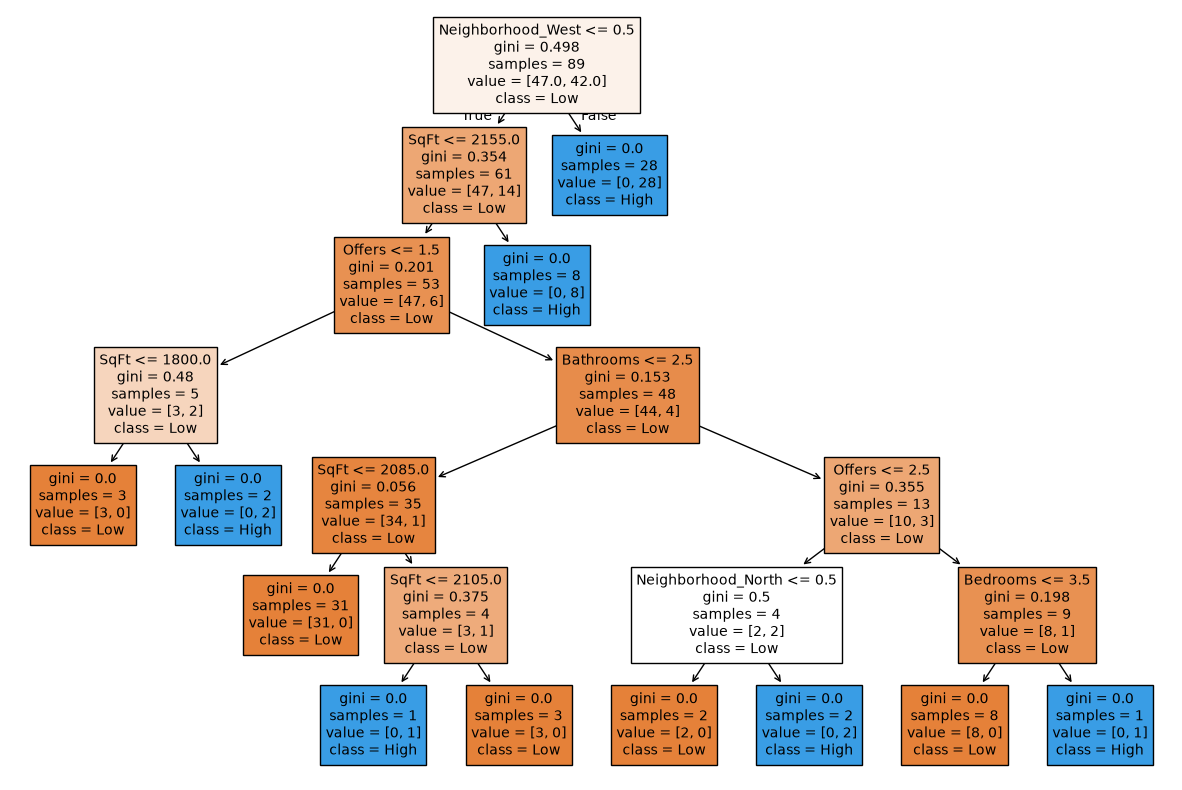

In [39]:
from matplotlib import pyplot as plt
from sklearn.tree import plot_tree

plt.figure(figsize=(15,10))
plot_tree(dtc_model, feature_names=x.columns.tolist(), fontsize=10, class_names=["Low", "High"], filled = True)
plt.show()

## 3. Pruning 가지치기

In [41]:
dtc = DecisionTreeClassifier(criterion="gini", max_depth=3) # maximum number of question it's going to ask = 3
dtc_model = dtc.fit(x_train, y_train)
y_pred = dtc_model.predict(x_test)
metrics.accuracy_score(y_test, y_pred)

0.7692307692307693

In [43]:
nums = range(1, 11)
list(nums)

for n in nums:
    dtc_n = DecisionTreeClassifier(criterion="gini", max_depth=n)
    dtc_model_n = dtc_n.fit(x_train, y_train)
    y_pred_n = dtc_model_n.predict(x_test)
    score = metrics.accuracy_score(y_test, y_pred_n)
    print(str(n) + ": " + str(score))

1: 0.717948717948718
2: 0.7692307692307693
3: 0.7692307692307693
4: 0.8205128205128205
5: 0.8205128205128205
6: 0.8461538461538461
7: 0.8461538461538461
8: 0.8461538461538461
9: 0.8461538461538461
10: 0.8461538461538461
